# Воспроизведение результатов статьи о барьерной регуляризации линейной регрессии

*Reproduction notebook for the article on point-repulsion (barrier) regularization of linear regression.
English summary at the end.*

**Статья:** Ферубко А. О., Казаков О. Д. Барьерная регуляризация линейной регрессии для исключения физически
невозможных прогнозов в адаптивной системе управления оперативной памятью гипервизора KVM // Вестник
Дагестанского государственного технического университета. Технические науки. 2026.
**Библиотека:** [trosna-linear-regression](https://github.com/89605502155/trosna-linear-regression),
[PyPI](https://pypi.org/project/trosna-linear-regression/).

Блокнот самодостаточен: библиотека ставится с PyPI, данные телеметрии KVM (47 записей, 5455 замеров) встроены
прямо в блокнот. Достаточно выполнить все ячейки по порядку (*Run All*), локально или в Google Colab. Полный
расчёт занимает несколько минут.

Что воспроизводится:

| Раздел | Статья |
|---|---|
| 1 | рис. «Ядра отталкивания» |
| 2 | рис. «Физическая аналогия» |
| 4 | рис. «Прогноз на 5 мониторингов вперёд (запись 0)» и «Прогноз на 3 мониторинга вперёд (запись 1)» |
| 5 | табл. 1, сводные результаты по всем записям |
| 6 | табл. 2, чувствительность к ширине зоны барьера |
| 7 | рис. «Нарушение условий оптимальности по итерациям метода Ньютона» и статистика сходимости |
| 8 | автоматическая сверка всех чисел с текстом статьи |

Блок-схемы (контур управления и алгоритм обучения) не являются результатами расчёта и здесь не строятся.

In [1]:
%pip install -q "trosna-linear-regression==0.1.0" numpy scipy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import base64
import gzip
import hashlib
import importlib.metadata as im
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq
from sklearn.linear_model import LinearRegression

from trosna_linear_regression import TrosnaLinearRegression, get_kernel

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "figure.dpi": 110,
    "legend.framealpha": 0.9,
})
for pkg in ("trosna-linear-regression", "numpy", "scipy", "scikit-learn", "matplotlib"):
    print(f"{pkg:26s}{im.version(pkg)}")

trosna-linear-regression  0.1.0
numpy                     2.5.4
scipy                     1.18.1
scikit-learn              1.9.1
matplotlib                3.11.2


## 0. Данные

Память, занятая гостевой ОС виртуальной машины под KVM, замер раз в ~2 с. Каждая строка: номер записи,
время от начала записи (с), занятая память (МБ). Данные хранятся ниже в виде CSV, сжатого gzip и закодированного
base64; контрольная сумма SHA-256 распакованного текста проверяется при загрузке.

In [3]:
DATA_SHA256 = "d894446ed6d0d80cab79e5e511fe4de8078995b0b3c39fdbccbad5a8d2e3af5e"
DATA = """
...
"""

raw = gzip.decompress(base64.b64decode("".join(DATA.split())))
assert hashlib.sha256(raw).hexdigest() == DATA_SHA256, "данные повреждены"
table = np.loadtxt(raw.decode().splitlines(), delimiter=",")
traces = {int(k): {"t": table[table[:, 0] == k, 1], "y": table[table[:, 0] == k, 2]}
          for k in np.unique(table[:, 0])}
print(f"записей: {len(traces)}, замеров: {len(table)}")
print("первые строки (запись, t, с, память, МБ):")
print(raw.decode().splitlines()[:5])

записей: 47, замеров: 5455
первые строки (запись, t, с, память, МБ):
['0,0,46.41', '0,2,46.41', '0,4,46.41', '0,6,46.41', '0,8,46.41']


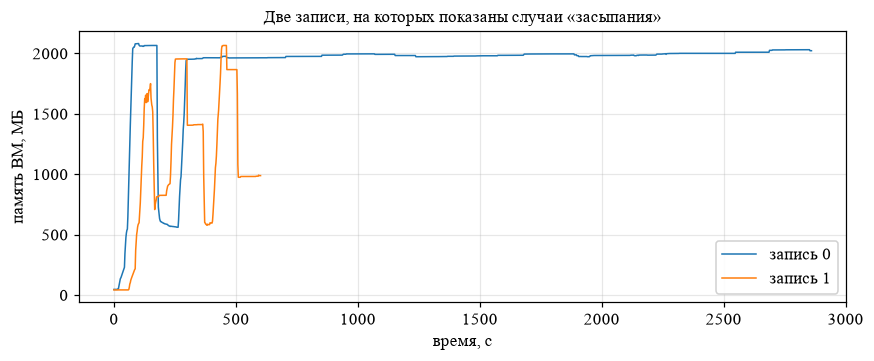

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for k in (0, 1):
    ax.plot(traces[k]["t"], traces[k]["y"], lw=1, label=f"запись {k}")
ax.set_xlabel("время, с")
ax.set_ylabel("память ВМ, МБ")
ax.set_title("Две записи, на которых показаны случаи «засыпания»", fontsize=11)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 1. Ядра отталкивания

Мягкие ядра (гауссово, Коши) ограничены и нормированы на кривизну $\varphi''(0) = -1$. Барьерные ядра
(логарифмическое и обратно-квадратичное) бесконечны в точке и равны нулю вне зоны $|d| < \sigma$.

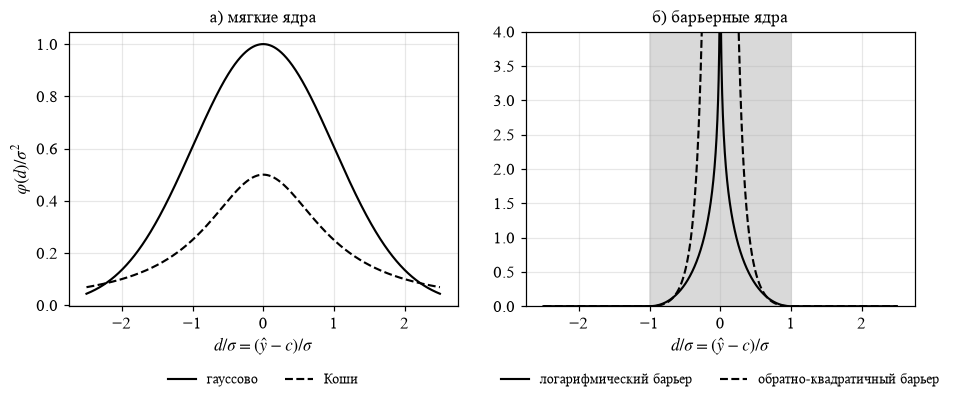

In [5]:
d = np.linspace(-2.5, 2.5, 2001)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.9))
styles = {"gaussian": ("гауссово", "-"), "cauchy": ("Коши", "--"),
          "log_barrier": ("логарифмический барьер", "-"), "inverse_barrier": ("обратно-квадратичный барьер", "--")}
for ax, names, title in [(axes[0], ["gaussian", "cauchy"], "а) мягкие ядра"),
                         (axes[1], ["log_barrier", "inverse_barrier"], "б) барьерные ядра")]:
    for name in names:
        label, ls = styles[name]
        ax.plot(d, get_kernel(name).value(d, 1.0), ls, color="black", lw=1.4, label=label)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(r"$d/\sigma = (\hat y - c)/\sigma$")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9, ncol=2, frameon=False)
axes[0].set_ylabel(r"$\varphi(d)/\sigma^2$")
axes[1].set_ylim(0, 4)
axes[1].axvspan(-1, 1, color="0.85", zorder=0)
fig.tight_layout()
plt.show()

## 2. Физическая аналогия

а) Энергия одного предсказания: квадратичная «пружина» к наблюдению плюс барьер у «электрода» в точке $c = 0$.
Равновесие — минимум полной энергии. б) Все предсказания лежат на одной прямой и движутся вместе с ней, как
бусины на жёстком стержне: поле, действующее на прогноз в момент $t^*$, поднимает и поворачивает всю прямую.

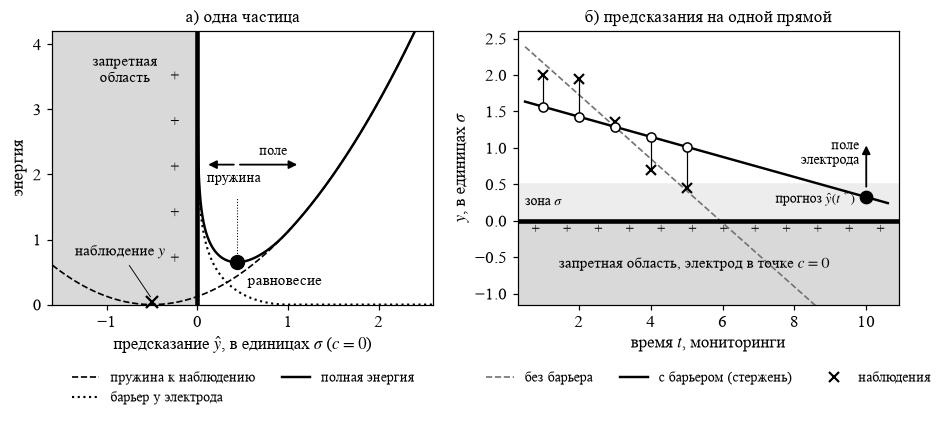

прогноз в t* = 10: без барьера -1.78, с барьером 0.33 (в единицах σ)


In [6]:
KERNEL = get_kernel("log_barrier")


def electrode(ax, x, y0, y1):
    ax.plot([x, x], [y0, y1], color="black", lw=3, solid_capstyle="butt", zorder=3)
    for y in np.linspace(y0, y1, 7)[1:-1]:
        ax.text(x - 0.06 * (ax.get_xlim()[1] - ax.get_xlim()[0]), y, "+", ha="center", va="center", fontsize=10)


def energy(ax):
    y_obs, a = -0.5, 0.5  # притягивающий центр в запретной области, сила барьера a = αρ
    z = np.linspace(-1.6, 2.6, 2001)
    zr = z[z > 1e-3]
    spring = 0.5 * (z - y_obs) ** 2
    barrier = a * KERNEL.value(zr, 1.0)
    total = 0.5 * (zr - y_obs) ** 2 + barrier
    force = lambda x: -(x - y_obs) - a * KERNEL.derivative(np.array([x]), 1.0)[0]  # noqa: E731
    eq = brentq(force, 1e-6, 1.0)
    u_eq = 0.5 * (eq - y_obs) ** 2 + a * KERNEL.value(np.array([eq]), 1.0)[0]

    ax.set_xlim(-1.6, 2.6)
    ax.set_ylim(0, 4.2)
    ax.axvspan(-1.6, 0, color="0.85", zorder=0)
    ax.text(-0.8, 3.85, "запретная\nобласть", ha="center", va="top", fontsize=10)
    ax.plot(z, spring, "--", color="black", lw=1.1, label="пружина к наблюдению")
    ax.plot(zr, barrier, ":", color="black", lw=1.4, label="барьер у электрода")
    ax.plot(zr, total, "-", color="black", lw=1.6, label="полная энергия")
    electrode(ax, 0, 0, 4.2)
    ax.plot([y_obs], [0.04], "x", color="black", ms=8, mew=1.5, clip_on=False, zorder=4)
    ax.annotate("наблюдение $y$", (y_obs, 0.08), (y_obs - 0.35, 0.75), ha="center", fontsize=10,
                arrowprops={"arrowstyle": "-", "lw": 0.6})
    ax.plot([eq], [u_eq], "o", color="black", ms=9, zorder=5)
    arrow = {"arrowstyle": "-|>", "lw": 1.2, "color": "black"}
    ya = u_eq + 1.5
    ax.plot([eq, eq], [u_eq, ya - 0.5], ":", color="black", lw=0.7)
    ax.annotate("", (eq - 0.35, ya), (eq, ya), arrowprops=arrow)
    ax.annotate("", (eq + 0.7, ya), (eq, ya), arrowprops=arrow)
    ax.text(eq - 0.33, ya - 0.12, "пружина", ha="left", va="top", fontsize=9)
    ax.text(eq + 0.4, ya + 0.15, "поле", ha="center", fontsize=9)
    ax.text(eq + 0.12, u_eq - 0.35, "равновесие", ha="left", fontsize=10)
    ax.set_xlabel(r"предсказание $\hat y$, в единицах $\sigma$ ($c = 0$)")
    ax.set_ylabel("энергия")
    ax.set_title("а) одна частица", fontsize=11)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9, ncol=2, frameon=False)


def rod(ax):
    t = np.arange(1.0, 6.0)
    y = np.array([2.0, 1.95, 1.35, 0.7, 0.45])
    t_star = 10.0
    w = 1.0 / np.abs(t_star - t)
    X, Xq = t[:, None], np.array([[t_star]])
    base = TrosnaLinearRegression(alpha=0.0).fit(X, y, w)
    ours = TrosnaLinearRegression(alpha=1.0, repulsion_ratio=1.0, kernel="log_barrier", repulsion_point=0.0,
                                  repulsion_side="above", repulsion_width=0.5).fit(X, y, w, repulsion_X=Xq)
    tt = np.linspace(0.5, 10.6, 200)[:, None]

    ax.set_xlim(0.3, 10.9)
    ax.set_ylim(-1.15, 2.6)
    ax.axhspan(-1.15, 0, color="0.85", zorder=0)
    ax.axhspan(0, 0.5, color="0.93", zorder=0)
    ax.plot([0.3, 10.9], [0, 0], color="black", lw=3, solid_capstyle="butt", zorder=3)
    for x in np.linspace(0.8, 10.4, 12):
        ax.text(x, -0.12, "+", ha="center", va="center", fontsize=9)
    ax.text(5.2, -0.65, "запретная область, электрод в точке $c = 0$", ha="center", fontsize=10)
    ax.text(0.5, 0.25, r"зона $\sigma$", ha="left", va="center", fontsize=9)
    ax.plot(tt[:, 0], base.predict(tt), "--", color="0.45", lw=1.1, label="без барьера")
    ax.plot(tt[:, 0], ours.predict(tt), "-", color="black", lw=1.6, label="с барьером (стержень)")
    pred = ours.predict(X)
    for ti, yi, pi in zip(t, y, pred):
        ax.plot([ti, ti], [yi, pi], color="black", lw=0.8, zorder=2)  # пружина к наблюдению
    ax.plot(t, y, "x", color="black", ms=7, mew=1.4, label="наблюдения", zorder=4)
    ax.plot(t, pred, "o", color="white", mec="black", ms=6, zorder=5)
    p_star = ours.predict(Xq)[0]
    ax.plot([t_star], [p_star], "o", color="black", ms=8, zorder=5)
    ax.annotate("", (t_star, p_star + 0.75), (t_star, p_star + 0.1),
                arrowprops={"arrowstyle": "-|>", "lw": 1.2, "color": "black"})
    ax.text(t_star - 0.2, p_star + 0.6, "поле\nэлектрода", ha="right", va="center", fontsize=9)
    ax.text(t_star - 0.3, p_star - 0.02, r"прогноз $\hat y(t^*)$", ha="right", va="center", fontsize=9)
    ax.set_xlabel("время $t$, мониторинги")
    ax.set_ylabel(r"$y$, в единицах $\sigma$")
    ax.set_title("б) предсказания на одной прямой", fontsize=11)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9, ncol=3, frameon=False)
    return float(base.predict(Xq)[0]), float(p_star)


fig, axes = plt.subplots(1, 2, figsize=(9, 4.1))
energy(axes[0])
base_star, ours_star = rod(axes[1])
fig.tight_layout()
plt.show()
print(f"прогноз в t* = 10: без барьера {base_star:.2f}, с барьером {ours_star:.2f} (в единицах σ)")

## 3. Базовая модель и модель с барьером

Базовая модель строит прямую по $W = 5$ последним замерам с весами $w_i = |t^* - t_i|^{-1}$, где $t^*$ —
момент прогноза. Это `LinearRegression` из scikit-learn с `sample_weight`. Прогноз делается на $h$ мониторингов
вперёд.

Модель с барьером — `TrosnaLinearRegression` с логарифмическим барьером в точке $c = 0$, разрешённой стороной
«выше» (`repulsion_side="above"`), шириной зоны $\sigma = 100$ МБ; момент прогноза $t^*$ передаётся в
`repulsion_X`, чтобы барьер действовал и на сам прогноз. Для сравнения приведена простая обрезка прогноза
нулём.

In [7]:
WINDOW, POWER, LIMIT, WIDTH, ALPHA = 5, 1.0, 0.0, 100.0, 1.0


def weights(t_window, t_target):
    return np.abs(t_target - t_window) ** -POWER


def barrier_model(kernel="log_barrier", width=WIDTH, alpha=ALPHA):
    return TrosnaLinearRegression(alpha=alpha, repulsion_ratio=1.0, kernel=kernel, repulsion_point=LIMIT,
                                  repulsion_side="above", repulsion_width=width)


def rolling(t, y, h, **kw):
    # Прогнозы на h шагов вперёд по скользящему окну: базовый, обрезанный, с барьером.
    rows = []
    for k in range(WINDOW, len(y) - h + 1):
        tw, yw, tn = t[k - WINDOW:k], y[k - WINDOW:k], t[k + h - 1]
        w = weights(tw, tn)
        base = LinearRegression().fit(tw[:, None], yw, sample_weight=w).predict([[tn]])[0]
        m = barrier_model(**kw).fit(tw[:, None], yw, w, repulsion_X=[[tn]])
        rows.append((k + h - 1, base, max(base, LIMIT), m.predict([[tn]])[0], m.converged_, m.n_iter_, m.optimality_))
    r = np.array(rows, dtype=float)
    return {"idx": r[:, 0].astype(int), "base": r[:, 1], "clip": r[:, 2], "ours": r[:, 3],
            "converged": r[:, 4].astype(bool), "n_iter": r[:, 5], "optimality": r[:, 6]}

## 4. «Засыпание» базовой модели на реальных записях

Запись 0: после полки около 2066 МБ потребление падает за несколько секунд до ~600 МБ. Прогноз базовой модели на
5 мониторингов (~10 с) вперёд уходит глубоко ниже нуля, прогноз с барьером остаётся положительным.

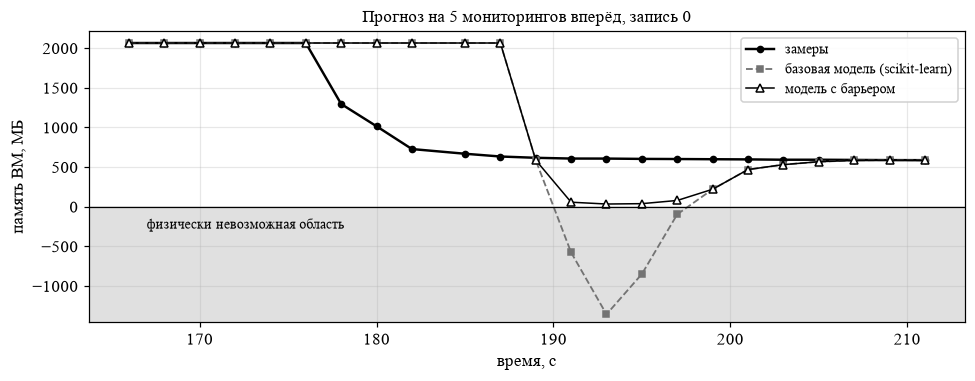

t=  191 с: факт   608.3  базовая   -576.2  с барьером   57.7
t=  193 с: факт   607.9  базовая  -1356.7  с барьером   34.7
t=  195 с: факт   603.9  базовая   -848.3  с барьером   39.3
t=  197 с: факт   602.3  базовая    -95.2  с барьером   79.6


In [8]:
def plot_case(trace, h, lo, hi, title):
    t, y = traces[trace]["t"], traces[trace]["y"]
    r = rolling(t, y, h)
    sel = (r["idx"] >= lo) & (r["idx"] <= hi)
    tt = t[r["idx"][sel]]
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.axhspan(-2000, LIMIT, color="0.88", zorder=0)
    ax.text(t[lo] + 1, -150, "физически невозможная область", fontsize=9, va="top")
    ax.plot(t[lo:hi + 1], y[lo:hi + 1], "o-", color="black", lw=1.6, ms=4, label="замеры")
    ax.plot(tt, r["base"][sel], "s--", color="0.45", lw=1.2, ms=4, label="базовая модель (scikit-learn)")
    ax.plot(tt, r["ours"][sel], "^-", color="black", lw=1.0, ms=5, mfc="white", label="модель с барьером")
    ax.axhline(LIMIT, color="black", lw=0.8)
    ax.set_ylim(min(-200, r["base"][sel].min() - 100), y[lo:hi + 1].max() + 150)
    ax.set_xlabel("время, с")
    ax.set_ylabel("память ВМ, МБ")
    ax.set_title(title, fontsize=11)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=9)
    fig.tight_layout()
    plt.show()
    for j in np.flatnonzero(sel & (r["base"] <= LIMIT)):
        k = r["idx"][j]
        print(f"t={t[k]:5.0f} с: факт {y[k]:7.1f}  базовая {r['base'][j]:8.1f}  с барьером {r['ours'][j]:6.1f}")
    return {"min_base": float(r["base"][sel].min()), "min_ours": float(r["ours"][sel].min())}


case_drop = plot_case(0, 5, 82, 104, "Прогноз на 5 мониторингов вперёд, запись 0")

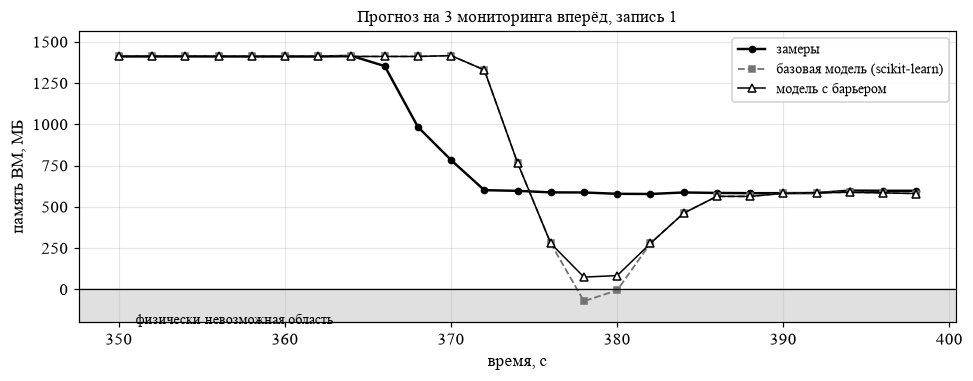

t=  378 с: факт   586.5  базовая    -72.2  с барьером   73.7
t=  380 с: факт   578.5  базовая     -5.8  с барьером   82.9


In [9]:
case_drop2 = plot_case(1, 3, 172, 196, "Прогноз на 3 мониторинга вперёд, запись 1")

## 5. Таблица 1: сводка по всем записям

Для каждого горизонта $h$: число прогнозов в недопустимой области $\hat y \le 0$, наименьший прогноз, средняя
абсолютная ошибка $\mathrm{MAE} = \frac1N\sum|y_k - \hat y_k|$ и средняя недодача памяти
$D = \frac1N\sum\max(0,\, y_k - \hat y_k)$. Заодно проверяется, что каждое обучение модели с барьером сошлось.

In [10]:
summary = {}
t0 = time.time()
for h in (1, 3, 5):
    acc = {key: [] for key in ("y", "base", "clip", "ours", "converged", "n_iter", "optimality")}
    for tr in traces.values():
        r = rolling(tr["t"], tr["y"], h)
        acc["y"].append(tr["y"][r["idx"]])
        for key in ("base", "clip", "ours", "converged", "n_iter", "optimality"):
            acc[key].append(r[key])
    a = {k: np.concatenate(v) for k, v in acc.items()}
    row = {"n": int(a["y"].size), "all_converged": bool(a["converged"].all()),
           "median_iter": float(np.median(a["n_iter"])), "max_iter": int(a["n_iter"].max())}
    for m in ("base", "clip", "ours"):
        err = a[m] - a["y"]
        row[m] = {"bad": int(np.sum(a[m] <= LIMIT)), "min": float(a[m].min()), "mae": float(np.mean(np.abs(err))),
                  "shortfall": float(np.mean(np.maximum(0, -err)))}
    summary[h] = row
print(f"время расчёта: {time.time() - t0:.0f} с\n")
print(f"{'h':>2} {'модель':>17} {'ŷ≤0':>5} {'min ŷ, МБ':>10} {'MAE, МБ':>8} {'D, МБ':>7}")
names = {"base": "базовая", "clip": "обрезка нулём", "ours": "с барьером"}
for h, row in summary.items():
    for m in ("base", "clip", "ours"):
        s = row[m]
        print(f"{h:>2} {names[m]:>17} {s['bad']:>5} {s['min']:>10.1f} {s['mae']:>8.1f} {s['shortfall']:>7.1f}")
    print(f"   прогнозов: {row['n']}, все обучения сошлись: {row['all_converged']}\n")

время расчёта: 74 с

 h            модель   ŷ≤0  min ŷ, МБ  MAE, МБ   D, МБ
 1           базовая     6      -91.9     27.4    13.6
 1     обрезка нулём     6        0.0     27.4    13.6
 1        с барьером     0       37.1     28.1    13.4
   прогнозов: 5220, все обучения сошлись: True

 3           базовая    53     -607.9     78.4    38.2
 3     обрезка нулём    53        0.0     77.0    36.8
 3        с барьером     0       23.9     76.7    35.7
   прогнозов: 5126, все обучения сошлись: True

 5           базовая   128    -1356.7    137.1    67.1
 5     обрезка нулём   128        0.0    130.3    60.2
 5        с барьером     0       23.0    128.4    57.7
   прогнозов: 5032, все обучения сошлись: True



## 6. Таблица 2: чувствительность к ширине зоны барьера

Горизонт 5 мониторингов, модель с барьером при разной ширине $\sigma$.

In [11]:
sens = {}
print(f"{'σ, МБ':>6} {'ŷ≤0':>5} {'min ŷ, МБ':>10} {'MAE, МБ':>8} {'D, МБ':>7}")
for width in (25.0, 50.0, 100.0, 200.0, 400.0):
    ys, ours = [], []
    for tr in traces.values():
        r = rolling(tr["t"], tr["y"], 5, width=width)
        ys.append(tr["y"][r["idx"]])
        ours.append(r["ours"])
    ys, ours = np.concatenate(ys), np.concatenate(ours)
    s = sens[width] = {"bad": int(np.sum(ours <= LIMIT)), "min": float(ours.min()),
                       "mae": float(np.mean(np.abs(ours - ys))), "shortfall": float(np.mean(np.maximum(0, ys - ours)))}
    print(f"{width:>6.0f} {s['bad']:>5} {s['min']:>10.1f} {s['mae']:>8.1f} {s['shortfall']:>7.1f}")

 σ, МБ   ŷ≤0  min ŷ, МБ  MAE, МБ   D, МБ


    25     0        1.6    129.9    59.9


    50     0        6.1    129.4    59.3


   100     0       23.0    128.4    57.7


   200     0       76.8    126.3    53.6


   400     0      215.8    129.2    43.8


## 7. Сходимость метода Ньютона

Нарушение условий оптимальности по итерациям (в долях допуска) для обучений записи 0, где базовый прогноз на
5 шагов ниже нуля и барьер действует сильнее всего. Затем — статистика числа итераций по всем обучениям с
горизонтом 5.

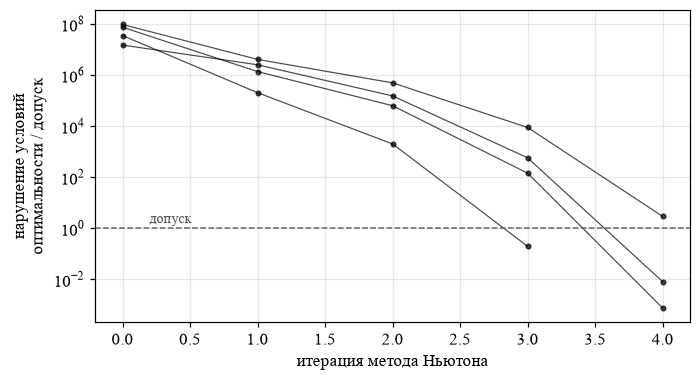

обучений на графике: 4, итераций: [3, 4, 4, 4]


In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
t, y = traces[0]["t"], traces[0]["y"]
conv_iters = []
for k in range(WINDOW, len(y) - 4):
    tw, yw, tn = t[k - WINDOW:k], y[k - WINDOW:k], t[k + 4]
    w = weights(tw, tn)
    base = LinearRegression().fit(tw[:, None], yw, sample_weight=w).predict([[tn]])[0]
    if base > LIMIT:
        continue
    m = barrier_model().fit(tw[:, None], yw, w, repulsion_X=[[tn]])
    hist = m.optimality_history_ / m.tolerance_
    ax.semilogy(np.arange(hist.size), np.maximum(hist, 1e-6), "o-", color="black", lw=0.8, ms=3, alpha=0.7)
    conv_iters.append(hist.size - 1)
ax.axhline(1.0, color="0.4", ls="--", lw=1)
ax.text(0.2, 1.6, "допуск", fontsize=9, color="0.3")
ax.set_xlabel("итерация метода Ньютона")
ax.set_ylabel("нарушение условий\nоптимальности / допуск")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
print(f"обучений на графике: {len(conv_iters)}, итераций: {conv_iters}")

In [13]:
all_iters = []
for tr in traces.values():
    t, y = tr["t"], tr["y"]
    for k in range(WINDOW, len(y) - 4):
        tw, yw, tn = t[k - WINDOW:k], y[k - WINDOW:k], t[k + 4]
        m = barrier_model().fit(tw[:, None], yw, weights(tw, tn), repulsion_X=[[tn]])
        all_iters.append(m.optimality_history_.size - 1)
all_iters = np.array(all_iters)
newton = {"fits": int(all_iters.size), "active": int(np.sum(all_iters > 0)),
          "p99": float(np.percentile(all_iters, 99)), "max": int(all_iters.max())}
print(f"обучений: {newton['fits']}, барьер активен: {newton['active']}, "
      f"итераций: 99-й процентиль {newton['p99']:.0f}, максимум {newton['max']}")

обучений: 5032, барьер активен: 344, итераций: 99-й процентиль 4, максимум 12


## 8. Сверка с текстом статьи

Числа, напечатанные в статье, сравниваются с только что посчитанными (с точностью округления в статье).

In [14]:
ARTICLE = {
    # табл. 1: h -> модель -> (прогнозов ŷ≤0, наименьший прогноз, MAE, D)
    "t1": {1: {"base": (6, -91.9, 27.4, 13.6), "clip": (6, 0.0, 27.4, 13.6), "ours": (0, 37.1, 28.1, 13.4)},
           3: {"base": (53, -607.9, 78.4, 38.2), "clip": (53, 0.0, 77.0, 36.8), "ours": (0, 23.9, 76.7, 35.7)},
           5: {"base": (128, -1356.7, 137.1, 67.1), "clip": (128, 0.0, 130.3, 60.2), "ours": (0, 23.0, 128.4, 57.7)}},
    # табл. 2: σ -> (прогнозов ŷ≤0, наименьший прогноз, MAE, D)
    "t2": {25.0: (0, 1.6, 129.9, 59.9), 50.0: (0, 6.1, 129.4, 59.3), 100.0: (0, 23.0, 128.4, 57.7),
           200.0: (0, 76.8, 126.3, 53.6), 400.0: (0, 215.8, 129.2, 43.8)},
    "case_drop": (-1357, 35),  # наименьший прогноз базовой модели и модели с барьером на рис. для записи 0, МБ
    "n_fits": 15378, "fits_h5": 5032, "active_fits": 344, "p99_iter": 4, "max_iter": 12,
}

checks = []


def check(name, got, want, tol):
    ok = abs(got - want) <= tol
    checks.append(ok)
    print(f"{'OK ' if ok else 'ОТЛИЧИЕ'}  {name:45s} статья {want:>9}  расчёт {got:>11.3f}")


for h, models in ARTICLE["t1"].items():
    for m, (bad, mn, mae, d) in models.items():
        s = summary[h][m]
        check(f"табл.1 h={h} {names[m]}: ŷ≤0", s["bad"], bad, 0)
        check(f"табл.1 h={h} {names[m]}: min ŷ", s["min"], mn, 0.051)
        check(f"табл.1 h={h} {names[m]}: MAE", s["mae"], mae, 0.051)
        check(f"табл.1 h={h} {names[m]}: D", s["shortfall"], d, 0.051)
for w, (bad, mn, mae, d) in ARTICLE["t2"].items():
    s = sens[w]
    check(f"табл.2 σ={w:.0f}: ŷ≤0", s["bad"], bad, 0)
    check(f"табл.2 σ={w:.0f}: min ŷ", s["min"], mn, 0.051)
    check(f"табл.2 σ={w:.0f}: MAE", s["mae"], mae, 0.051)
    check(f"табл.2 σ={w:.0f}: D", s["shortfall"], d, 0.051)
check("рис. запись 0: min базовой", case_drop["min_base"], ARTICLE["case_drop"][0], 0.51)
check("рис. запись 0: min с барьером", case_drop["min_ours"], ARTICLE["case_drop"][1], 0.51)
check("всего обучений с барьером", sum(r["n"] for r in summary.values()), ARTICLE["n_fits"], 0)
check("все обучения сошлись", all(r["all_converged"] for r in summary.values()), True, 0)
check("обучений на h=5", newton["fits"], ARTICLE["fits_h5"], 0)
check("из них с активным барьером", newton["active"], ARTICLE["active_fits"], 0)
check("99-й процентиль итераций Ньютона", newton["p99"], ARTICLE["p99_iter"], 0)
check("наибольшее число итераций Ньютона", newton["max"], ARTICLE["max_iter"], 0)
print(f"\nсовпало {sum(checks)} из {len(checks)}")
assert all(checks), "есть расхождения с текстом статьи"

OK   табл.1 h=1 базовая: ŷ≤0                       статья         6  расчёт       6.000
OK   табл.1 h=1 базовая: min ŷ                     статья     -91.9  расчёт     -91.895
OK   табл.1 h=1 базовая: MAE                       статья      27.4  расчёт      27.429
OK   табл.1 h=1 базовая: D                         статья      13.6  расчёт      13.617
OK   табл.1 h=1 обрезка нулём: ŷ≤0                 статья         6  расчёт       6.000
OK   табл.1 h=1 обрезка нулём: min ŷ               статья       0.0  расчёт       0.000
OK   табл.1 h=1 обрезка нулём: MAE                 статья      27.4  расчёт      27.385
OK   табл.1 h=1 обрезка нулём: D                   статья      13.6  расчёт      13.573
OK   табл.1 h=1 с барьером: ŷ≤0                    статья         0  расчёт       0.000
OK   табл.1 h=1 с барьером: min ŷ                  статья      37.1  расчёт      37.104
OK   табл.1 h=1 с барьером: MAE                    статья      28.1  расчёт      28.082
OK   табл.1 h=1 с барьером: D   

## English summary

This notebook is self-contained: it installs `trosna-linear-regression` from PyPI and carries the KVM guest-memory
telemetry (47 recordings, 5455 samples) inline. *Run All* redraws every data figure of the article (repulsion
kernels, the physical analogy, two "falling asleep" cases, Newton convergence), recomputes Tables 1 and 2, and
finally checks every number printed in the article against the fresh computation (section 8).